<a href="https://colab.research.google.com/github/fernsoyson6453/Machine-learning_Project-2/blob/main/6971047221_Project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Project 2

Step 1: Import the Dataset

**Dataset:** CO2 Emission by countries Year wise (1750-2020)

**Downloaded from:**
https://www.kaggle.com/datasets/moazzimalibhatti/co2-emission-by-countries-year-wise-17502022/data

In [ ]:
# mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Project_2_6971047221/CO2 emission by countries.csv", encoding='latin1')
df.head()

,Country,Code,Calling Code,Year,CO2 emission (Tons),Population(2020),Area,% of World,Density(km2)
0,Afghanistan,AF,93,1750,0.0,41128771.0,652230.0,0.40%,63/km²
1,Afghanistan,AF,93,1751,0.0,41128771.0,652230.0,0.40%,63/km²
2,Afghanistan,AF,93,1752,0.0,41128771.0,652230.0,0.40%,63/km²
3,Afghanistan,AF,93,1753,0.0,41128771.0,652230.0,0.40%,63/km²
4,Afghanistan,AF,93,1754,0.0,41128771.0,652230.0,0.40%,63/km²


Step 2: Explore the Dataset

In [ ]:
# Check dataset size
df.shape

(59620, 9)

In [ ]:
# Check data types and missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59620 entries, 0 to 59619
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Country              59620 non-null  object 
 1   Code                 57452 non-null  object 
 2   Calling Code         56097 non-null  object 
 3   Year                 59620 non-null  int64  
 4   CO2 emission (Tons)  59620 non-null  float64
 5   Population(2020)     53116 non-null  float64
 6   Area                 55284 non-null  float64
 7   % of World           55284 non-null  object 
 8   Density(km2)         53116 non-null  object 
dtypes: float64(3), int64(1), object(5)
memory usage: 4.1+ MB


In [ ]:
# Check missing values
df.isnull().sum()

,0
Country,0
Code,2168
Calling Code,3523
Year,0
CO2 emission (Tons),0
Population(2020),6504
Area,4336
% of World,4336
Density(km2),6504


In [ ]:
# Descriptive statistics
df.describe()

,Year,CO2 emission (Tons),Population(2020),Area
count,59620.000000,5.962000e+04,5.311600e+04,5.528400e+04
mean,1885.000000,1.034774e+09,3.992260e+07,6.522073e+05
std,78.231085,1.041652e+10,1.482365e+08,1.865483e+06
min,1750.000000,0.000000e+00,1.131200e+04,2.100000e+01
25%,1817.000000,0.000000e+00,1.770414e+06,1.770450e+04
50%,1885.000000,0.000000e+00,8.673095e+06,1.103815e+05
75%,1953.000000,8.715092e+06,2.862920e+07,4.925730e+05
max,2020.000000,4.170000e+11,1.425887e+09,1.709824e+07


Step 3: Data Preparation / Preprocessing

In [ ]:
# 1. Filter data from 1960 onwards to focus on modern industrial emissions
df_clean = df[df['Year'] >= 1960].copy()

# 2. Clean string formatting in '% of World' and 'Density(km2)' and convert to numeric
df_clean['% of World'] = df_clean['% of World'].astype(str).str.replace('%', '', regex=False)
df_clean['% of World'] = pd.to_numeric(df_clean['% of World'], errors='coerce')

df_clean['Density(km2)'] = (
    df_clean['Density(km2)'].astype(str)
    .str.replace('/km²', '', regex=False)
    .str.replace(',', '', regex=False)
)
df_clean['Density(km2)'] = pd.to_numeric(df_clean['Density(km2)'], errors='coerce')

# 3. Remove rows with non-positive or missing CO2 emissions
df_clean = df_clean.dropna(subset=['CO2 emission (Tons)'])
df_clean = df_clean[df_clean['CO2 emission (Tons)'] > 0].copy()

# Sort chronologically by Country and Year
df_clean = df_clean.sort_values(['Country', 'Year']).reset_index(drop=True)

In [ ]:
# 1. Filter data from 1960 onwards (remove early industrial years where most values are 0)
df_clean = df[df['Year'] >= 1960].copy()

# 2. Clean string columns ('% of World' and 'Density(km2)') and convert to float
df_clean['% of World'] = df_clean['% of World'].astype(str).str.replace('%', '', regex=False)
df_clean['% of World'] = pd.to_numeric(df_clean['% of World'], errors='coerce')

df_clean['Density(km2)'] = (
    df_clean['Density(km2)'].astype(str)
    .str.replace('/km²', '', regex=False)
    .str.replace(',', '', regex=False)
)
df_clean['Density(km2)'] = pd.to_numeric(df_clean['Density(km2)'], errors='coerce')

# 3. Filter out rows where CO2 emission is 0 or negative
df_clean = df_clean[df_clean['CO2 emission (Tons)'] > 0].copy()

# Sort by Country and Year before creating lag features
df_clean = df_clean.sort_values(['Country', 'Year']).reset_index(drop=True)

print("Cleaned Dataset Shape:", df_clean.shape)
df_clean[['Country', 'Year', 'CO2 emission (Tons)', '% of World', 'Density(km2)']].head()

Cleaned Dataset Shape: (12820, 9)


,Country,Year,CO2 emission (Tons),% of World,Density(km2)
0,Afghanistan,1960,2253064.0,0.4,63.0
1,Afghanistan,1961,2743862.0,0.4,63.0
2,Afghanistan,1962,3432456.0,0.4,63.0
3,Afghanistan,1963,4139192.0,0.4,63.0
4,Afghanistan,1964,4977743.0,0.4,63.0


Step 4: Feature Engineering

In [ ]:
# 1. Lag features: previous 1-year and 2-year CO2 emissions for each country
df_clean['CO2_Lag1'] = df_clean.groupby('Country')['CO2 emission (Tons)'].shift(1)
df_clean['CO2_Lag2'] = df_clean.groupby('Country')['CO2 emission (Tons)'].shift(2)

# 2. Year-over-Year (YoY) emission growth
df_clean['CO2_Diff1'] = df_clean['CO2_Lag1'] - df_clean['CO2_Lag2']

# 3. Population-to-Area ratio
df_clean['Pop_Area_Ratio'] = df_clean['Population(2020)'] / (df_clean['Area'] + 1)

# Drop rows with NaN created by shift()
df_clean = df_clean.dropna(subset=['CO2_Lag1', 'CO2_Lag2', 'CO2_Diff1']).reset_index(drop=True)

# Log-transform the target variable to reduce right-skewness
df_clean['Log_CO2'] = np.log1p(df_clean['CO2 emission (Tons)'])

print("Dataset Shape after Feature Engineering:", df_clean.shape)

Dataset Shape after Feature Engineering: (12380, 14)


Step 5: Train-Test Split & Build 6 ML Models

In [ ]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

features = [
   'Year', 'Population(2020)', 'Area', '% of World', 'Density(km2)', 'Pop_Area_Ratio'
]
target = 'Log_CO2'

# Chronological split: Train (1962-2013), Test (2014-2020)
# (โปรดตรวจสอบให้แน่ใจว่าได้รันเซลล์ก่อนหน้าเพื่อสร้าง df_clean แล้ว)
train_df = df_clean[df_clean['Year'] <= 2013]
test_df = df_clean[df_clean['Year'] > 2013]

X_train, y_train = train_df[features], train_df[target]
X_test, y_test = test_df[features], test_df[target]

# Impute any remaining missing values and scale features
preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Define 6 regression models
models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "K-Nearest Neighbors": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=150, learning_rate=0.05, random_state=42, n_jobs=-1)
}

results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })


# creat Summary Table
summary_df = pd.DataFrame(results)
display(summary_df)

,Model,MAE,RMSE,R2
0,Ridge Regression,2.160525,2.636444,0.190054
1,K-Nearest Neighbors,1.404068,1.790907,0.626264
2,Decision Tree,1.118137,1.432496,0.760886
3,Random Forest,0.262130,0.610838,0.956522
4,Gradient Boosting,0.790604,1.069347,0.866753
5,XGBoost,0.503219,0.762344,0.932279


Step 6 & 7: Hyperparameter Tuning & Model Evaluation

Best Parameters: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100}
Tuned XGBoost -> MAE: 1.4618 | RMSE: 1.8155 | R2: 0.6160


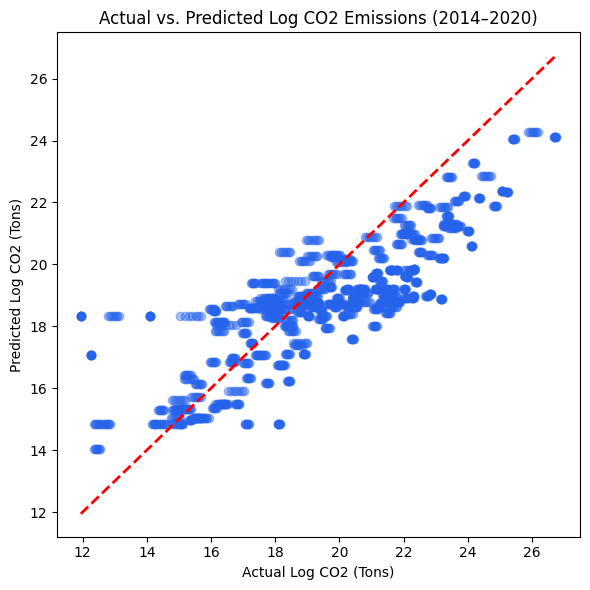

In [ ]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1]
}

tscv = TimeSeriesSplit(n_splits=4)
grid_xgb = GridSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_grid, cv=tscv, scoring='neg_root_mean_squared_error', n_jobs=-1
)
grid_xgb.fit(X_train_scaled, y_train)
best_xgb = grid_xgb.best_estimator_

print("Best Parameters:", grid_xgb.best_params_)

y_pred_best = best_xgb.predict(X_test_scaled)
print(f"Tuned XGBoost -> MAE: {mean_absolute_error(y_test, y_pred_best):.4f} | "
      f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_best)):.4f} | "
      f"R2: {r2_score(y_test, y_pred_best):.4f}")

# Plot Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_best, alpha=0.4, color='#2563eb')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs. Predicted Log CO2 Emissions (2014–2020)')
plt.xlabel('Actual Log CO2 (Tons)')
plt.ylabel('Predicted Log CO2 (Tons)')
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=300)
plt.show()

Step 8: Feature Importance & Explainable ML (SHAP)

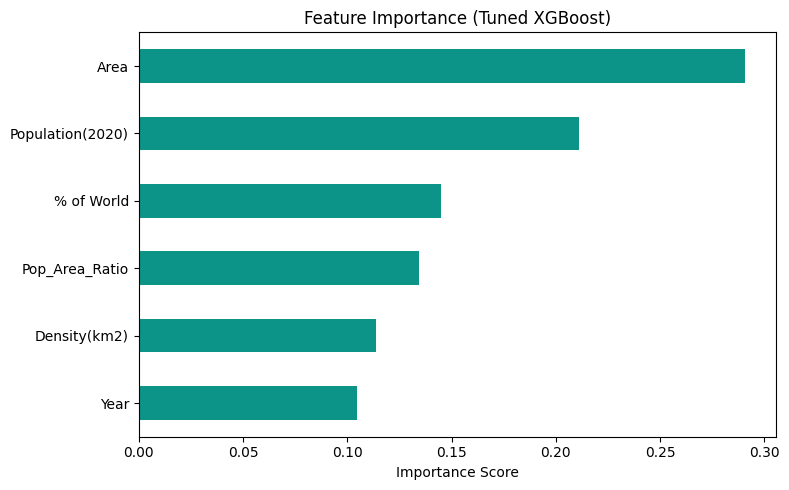

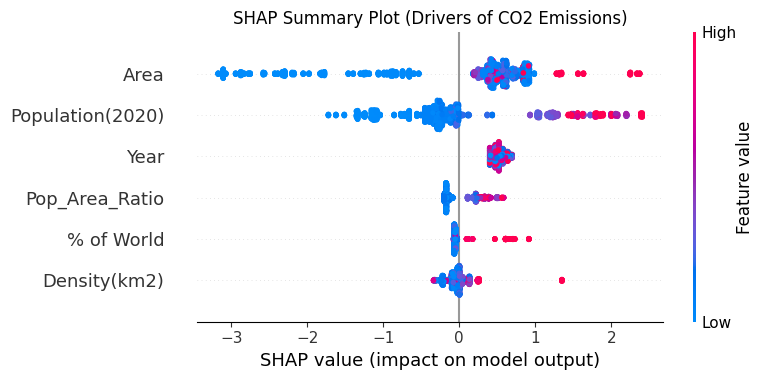

In [ ]:
import shap

# 1. Feature Importance Bar Chart
importances = pd.Series(best_xgb.feature_importances_, index=features).sort_values(ascending=True)
plt.figure(figsize=(8, 5))
importances.plot(kind='barh', color='#0d9488')
plt.title('Feature Importance (Tuned XGBoost)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

# 2. SHAP Summary Plot
explainer = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test_scaled)

plt.figure()
shap.summary_plot(shap_values, pd.DataFrame(X_test_scaled, columns=features), show=False)
plt.title('SHAP Summary Plot (Drivers of CO2 Emissions)')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()